# Video 2: Registration

Notes for this notebook.

This notebook generates the visuals used in the second video of the Multimodal Spatial Biology series. The goal of this video is to explain why H and E, COMET, and Xenium do not naturally line up in the same coordinate space, what a similarity transform is, and how the provided alignment matrices bring them into a shared frame. We also show, honestly, where this registration falls short.

All output images are saved into outputs/video2, next to this notebook. That folder is also where the slide deck for this video will be placed.


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


## Load the dataset

For this video we only need H and E and COMET, no transcripts and no boundaries, so the load step stays fast.


In [5]:
from unumlocalia.io import DatasetLoader
import time

DATA_DIR = Path("data/UnumLocalia")
core_id = "core01_hcc"

t0 = time.time()
loader = DatasetLoader(str(DATA_DIR)).load(
    do_load_transcripts=False,
    load_boundaries=False,
    load_he=True,
    load_comet=True,
)
print("Load time in seconds:", round(time.time() - t0, 1))

he = loader.he_arrays[core_id]
markers = loader.comet_markers[core_id]
comet_dapi = loader.get_comet_channel(core_id, markers.index("DAPI"))

print("H and E shape:", he.shape)
print("COMET DAPI shape:", comet_dapi.shape)


Load time in seconds: 3.2
H and E shape: (5735, 5678, 3)
COMET DAPI shape: (4088, 4116)


In [6]:
%matplotlib inline

## The misalignment problem

H and E and COMET are captured on different instruments, at different times, sometimes at different resolutions. Even though they are imaging the same physical tissue, the resulting arrays do not share a coordinate system. If we just place both images on the same axes without correction, they will not line up.

The cell below plots each image in its own native pixel grid, side by side, so the mismatch is visible before we fix anything.


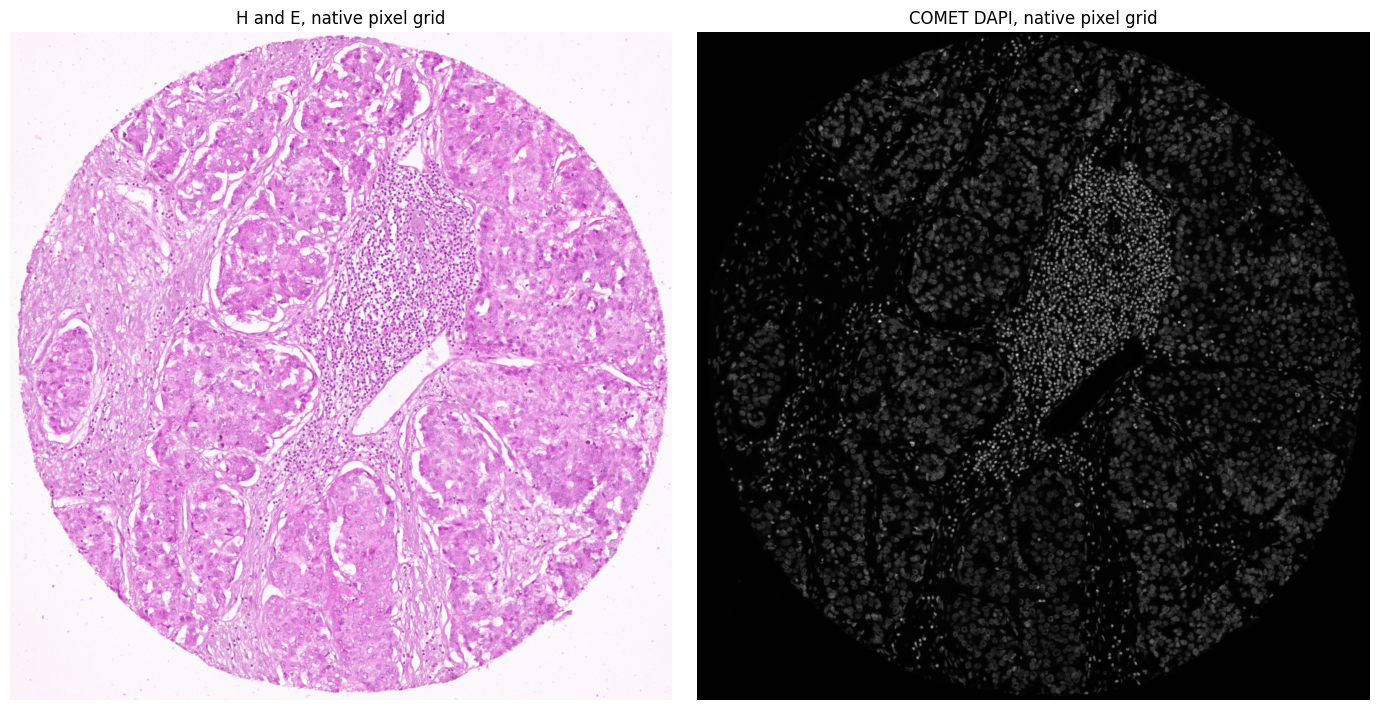

Saved slide_unregistered_layers.png


In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(he)
axes[0].set_title("H and E, native pixel grid")
axes[0].axis("off")

axes[1].imshow(comet_dapi, cmap="gray")
axes[1].set_title("COMET DAPI, native pixel grid")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_unregistered_layers.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_unregistered_layers.png")


## The alignment matrices

The dataset provides a precomputed affine matrix for each modality. Each matrix was built from matched keypoints, points a person or algorithm identified as the same physical location in both images, using a similarity transform. A similarity transform allows rotation, uniform scaling, and translation, but not shearing or local warping. This is the same approach known as Kabsch or Procrustes alignment, commonly used for this exact problem in spatial biology.

Two versions of each matrix are stored. The normalized version keeps only rotation and scale. The raw version also includes translation. We need the raw version to actually place both modalities on a shared canvas.

## Additional Notes about Registration:

### How this kind of registration is typically done

The dataset ships with the matrices already computed, but it helps to know how you would produce them yourself on a new dataset.

The general workflow has two parts.

**1. Finding matched keypoints.** You need pairs of points that represent the same physical location in both images, for example a distinctive nucleus or tissue landmark visible in both H and E and COMET DAPI. This can be done manually, clicking corresponding points in a tool like ImageJ or napari, or automatically, using feature detectors such as ORB or SIFT in OpenCV, though automatic matching is less reliable across different staining modalities since the images can look quite different from each other.

**2. Fitting the transform from those keypoints.** Once you have matched point pairs, fitting a similarity transform, rotation, uniform scale, and translation, is a standard least squares problem. A few common tools:

- `skimage.transform.SimilarityTransform().estimate(src, dst)` from scikit-image, fits exactly this kind of matrix from two arrays of matched points.
- `cv2.estimateAffinePartial2D(src, dst)` from OpenCV, similar in purpose, and includes built in RANSAC support to automatically down-weight bad keypoint matches.
- `scipy.spatial.procrustes` from SciPy, useful if you want the classic Procrustes formulation directly.

For more advanced cases, where a simple similarity transform is not enough and you need to correct local deformation rather than just global rotation and scale, dedicated image registration libraries such as SimpleITK or ANTsPy support non rigid registration. Some tools built specifically for whole slide histology registration, such as VALIS, are also worth knowing about if this becomes a recurring need.

We will not run any of this ourselves in this series, since the dataset already provides the matrices, but knowing the underlying approach helps when you eventually need to register your own multimodal data.

In [8]:
M_he_normalized = loader.alignment_matrices_he[core_id]
M_comet_normalized = loader.alignment_matrices_comet[core_id]

M_he_raw = loader.alignment_matrices_he_raw[core_id]
M_comet_raw = loader.alignment_matrices_comet_raw[core_id]

print("H and E, normalized (rotation and scale only)")
print(M_he_normalized)
print()
print("H and E, raw (includes translation)")
print(M_he_raw)
print()
print("COMET, normalized (rotation and scale only)")
print(M_comet_normalized)
print()
print("COMET, raw (includes translation)")
print(M_comet_raw)


H and E, normalized (rotation and scale only)
[[ 0.94190595 -0.00898292  0.        ]
 [ 0.00898292  0.94190595  0.        ]
 [ 0.          0.          1.        ]]

H and E, raw (includes translation)
[[ 9.41905953e-01 -8.98291971e-03  8.08261885e+03]
 [ 8.98291971e-03  9.41905953e-01  1.83962861e+04]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

COMET, normalized (rotation and scale only)
[[ 1.31385812  0.01719774  0.        ]
 [-0.01719774  1.31385812  0.        ]
 [ 0.          0.          1.        ]]

COMET, raw (includes translation)
[[ 1.31385812e+00  1.71977359e-02  7.99058778e+03]
 [-1.71977359e-02  1.31385812e+00  1.84700706e+04]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


## Building an aligned overlay

To bring both images into one shared view, we need to know the final canvas size. Each transform, when applied, moves the image to a new position. We compute where the corners of each image land after transformation, take the bounding box across both images, then shift everything so that bounding box starts at position zero, zero.

This logic is written as a reusable function, since we will apply it again to other cores later in the series.


In [9]:
import numpy as np
import cv2

def compute_shared_canvas(shapes_and_matrices):
    """
    Given a list of (image_shape, raw_affine_matrix) pairs, compute the
    bounding box that contains all images after transformation, and a
    shift matrix that moves that bounding box to start at (0, 0).
    Returns (canvas_width, canvas_height, shift_matrix).
    """
    all_corners = []
    for shape, M in shapes_and_matrices:
        h, w = shape[:2]
        corners = np.array([[0, 0, 1], [w, 0, 1], [0, h, 1], [w, h, 1]]).T
        transformed = (M @ corners)[:2, :].T
        all_corners.append(transformed)

    all_corners = np.vstack(all_corners)
    min_xy = all_corners.min(axis=0)
    max_xy = all_corners.max(axis=0)

    canvas_w = int(np.ceil(max_xy[0] - min_xy[0]))
    canvas_h = int(np.ceil(max_xy[1] - min_xy[1]))

    shift = np.array([
        [1, 0, -min_xy[0]],
        [0, 1, -min_xy[1]],
        [0, 0, 1],
    ])

    return canvas_w, canvas_h, shift


def warp_to_canvas(image, M_raw, shift, canvas_w, canvas_h):
    M_shifted = shift @ M_raw
    if image.ndim == 3:
        image_for_warp = image.mean(axis=2)
    else:
        image_for_warp = image.astype(float)
    return cv2.warpAffine(image_for_warp, M_shifted[:2, :], (canvas_w, canvas_h))


Canvas size: 5479 5453


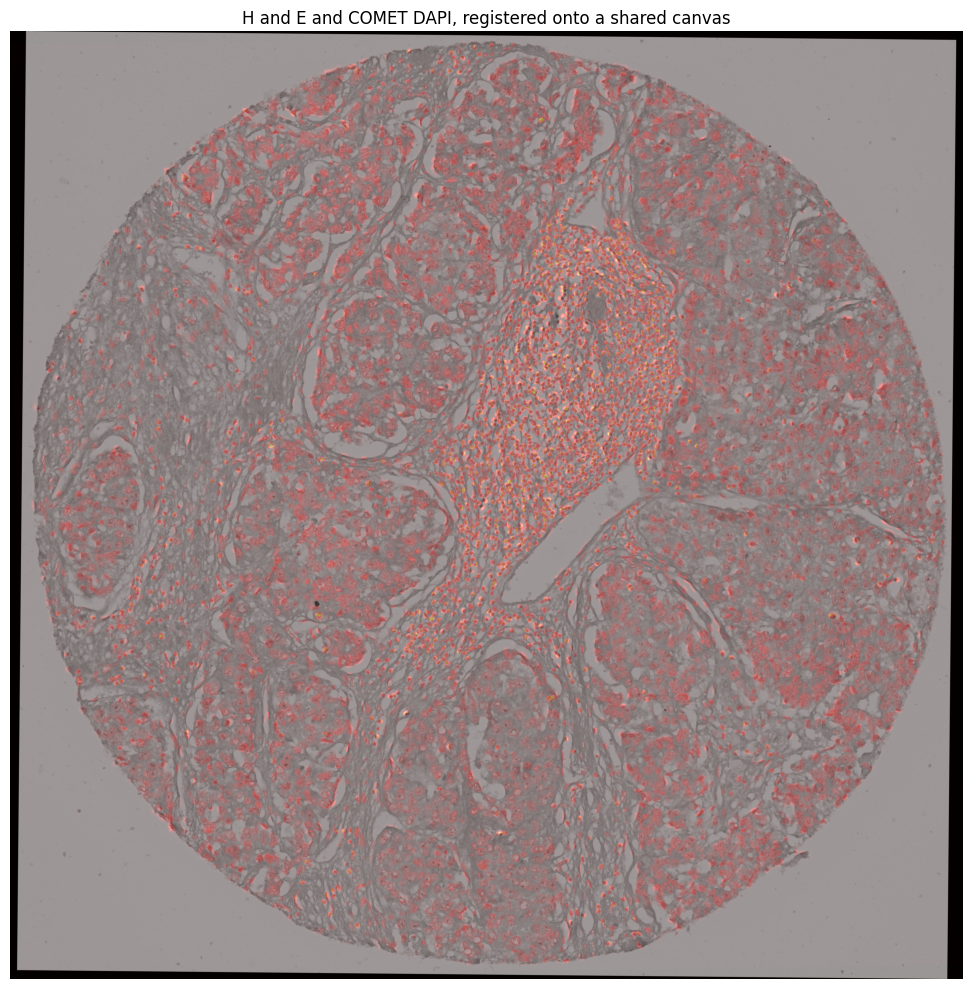

Saved slide_registered_overlay.png


In [10]:
canvas_w, canvas_h, shift = compute_shared_canvas([
    (he.shape, M_he_raw),
    (comet_dapi.shape, M_comet_raw),
])

print("Canvas size:", canvas_w, canvas_h)

he_on_canvas = warp_to_canvas(he, M_he_raw, shift, canvas_w, canvas_h)
comet_on_canvas = warp_to_canvas(comet_dapi, M_comet_raw, shift, canvas_w, canvas_h)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(he_on_canvas, cmap="gray")
ax.imshow(comet_on_canvas, cmap="hot", alpha=0.4)
ax.set_title("H and E and COMET DAPI, registered onto a shared canvas")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_registered_overlay.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_registered_overlay.png")


## Where registration falls short

A similarity transform corrects the overall position, rotation, and scale of an image, but it cannot correct local deformation, small stretches, tears, or folds that happen naturally between separate rounds of staining and imaging on the same physical section.

To show this honestly, we zoom into a small region of the registered overlay and look closely at individual nuclei. At this scale, small local offsets between the H and E structure and the COMET nuclear signal become visible, even though the overall tissue is clearly aligned at a glance.

Adjust the crop coordinates below if the region does not show the tissue clearly, this depends on where the tissue sits on the shared canvas for this particular core.


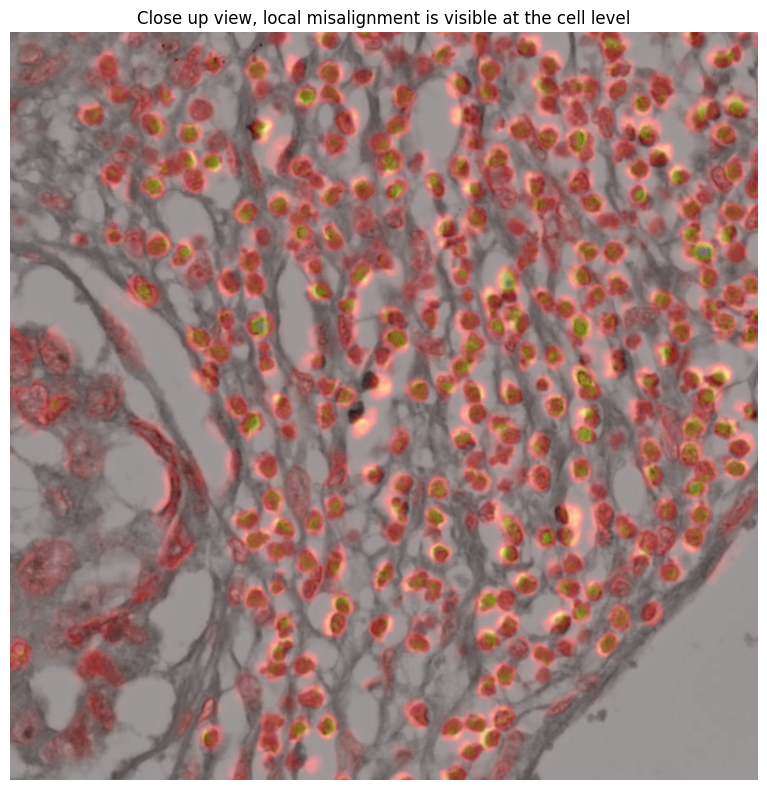

Saved slide_registration_limitation_zoom.png
If the crop looks empty, adjust crop_x and crop_y to a region where tissue is present.


In [12]:
crop_x, crop_y, crop_size = canvas_w // 2, canvas_h // 2, 400

x0, x1 = crop_x - crop_size, crop_x + crop_size
y0, y1 = crop_y - crop_size, crop_y + crop_size

he_crop = he_on_canvas[y0:y1, x0:x1]
comet_crop = comet_on_canvas[y0:y1, x0:x1]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(he_crop, cmap="gray")
ax.imshow(comet_crop, cmap="hot", alpha=0.4)
ax.set_title("Close up view, local misalignment is visible at the cell level")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_registration_limitation_zoom.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_registration_limitation_zoom.png")
print("If the crop looks empty, adjust crop_x and crop_y to a region where tissue is present.")


## Summary

We now have a reusable registration function, register_and_overlay logic through compute_shared_canvas and warp_to_canvas, that we will reuse in later videos, including when we repeat this same process on the non tumor core for comparison.

Registration gets us close enough for reliable per cell quantification at the tissue and neighborhood level, which is what the next episode focuses on. It is not pixel perfect at the single nucleus level, and that limitation is worth stating plainly rather than hiding it.

Next episode, we move from aligned images to actual per cell measurements, using Xenium derived cell boundaries as our spatial reference and quantifying COMET and transcript signal per cell.
